In [ ]:
# Resolve paths when launched from either the repository or notebooks folder.
from pathlib import Path
import os
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "pyproject.toml").is_file() and (p / "cyberhull").is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Launch this notebook from the CyberHull repository.")
os.chdir(PROJECT_ROOT)
Path("results/generated").mkdir(parents=True, exist_ok=True)


In [ ]:
# Cell 1: STEP 1 - Deep N-Dimensional Data Extraction
import json
import numpy as np
import pandas as pd
from collections import Counter

# --- STEP 1: DEEP N-DIMENSIONAL DATA EXTRACTION ---
print("Loading final_merged.json...")
with open("final_merged.json", "r", encoding="utf-8") as f:
    raw_text = f.read().strip()
    if raw_text.endswith(","): raw_text = raw_text[:-1]
    if not raw_text.startswith("["): raw_text = f"[{raw_text}]"
    records = json.loads(raw_text)

# First Pass: Find the top 85 most common keywords across all websites
all_keywords = Counter()
for rec in records:
    kw_scores = rec.get("keyword_scores", {})
    if isinstance(kw_scores, dict):
        for k in kw_scores.keys():
            all_keywords[k] += 1
top_keywords = [k for k, v in all_keywords.most_common(85)]

# Second Pass: Unpack and Build the 95-Dimensional Dataset
rows = []
for rec in records:
    flat_record = {}
    
    # 1. Target Label
    status_val = rec.get("status", None)
    if status_val == 1: flat_record["class"] = "Legitimate"
    elif status_val in [-1, 0]: flat_record["class"] = "Phishing"
    else: continue
    
    # 2. Extract Base Top-Level Math
    flat_record["main_entropy"] = float(rec.get("main_entropy", 0) or 0)
    flat_record["combined_entropy"] = float(rec.get("combined_entropy", 0) or 0)
    
    # 3. Unpack Lexical & Structural Dimensions (Derived Features)
    flat_record["url_length"] = len(str(rec.get("main_url", "")))
    flat_record["domain_length"] = len(str(rec.get("main_domain", "")))
    
    internal_pages = rec.get("internal_pages", []) or []
    flat_record["n_internal_pages"] = len(internal_pages)
    flat_record["n_external_links"] = len(rec.get("external_links", []) or [])
    
    # Calculate avg internal entropy
    int_entropies = [p.get("entropy", 0) for p in internal_pages if isinstance(p, dict) and isinstance(p.get("entropy"), (int, float))]
    flat_record["avg_internal_entropy"] = float(np.mean(int_entropies)) if int_entropies else 0.0
    
    # 4. Unpack Keyword Dimensions (The bulk of the 95 features)
    kw_scores = rec.get("keyword_scores", {})
    if isinstance(kw_scores, dict):
        for kw in top_keywords:
            flat_record[f"kw_{kw}"] = float(kw_scores.get(kw, 0.0))

    rows.append(flat_record)

# Build the final N-Dimensional DataFrame
df_raw = pd.DataFrame(rows).fillna(0) # Fill any missing data with 0
numeric_cols = df_raw.select_dtypes(include=[np.number]).columns

print("-" * 50)
print(f"Deep Extraction Complete!")
print(f"Total Websites Loaded: {df_raw.shape[0]}")
print(f"Total N-Dimensional Features Extracted: {len(numeric_cols)}")
print("-" * 50)

Loading final_merged.json...
--------------------------------------------------
Deep Extraction Complete!
Total Websites Loaded: 1674
Total N-Dimensional Features Extracted: 92
--------------------------------------------------


In [4]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.1 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.1 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.1 MB 2.0 MB/s eta 0:00:04
   --- ------------------------------------ 0.8/8.1 MB 2.3 MB/s eta 0:00:04
   ------ --------------------------------- 1.3/8.1 MB 1.7 MB/s eta 0:00:04
   --------- ------------------------------ 1.8/8.1 MB 2.0 MB/s eta 0:00:04
   ---------- ----------------------------- 2.1/8.1 MB 2.0 MB/s eta 0:00:04
   ------------ --------------------------- 2.6/8.1 MB 2.0 MB/s eta 0:00:03
   --------------- ------------------------ 3.1/8.1 MB 2.1 MB/s eta 0:00:03
   ------------------- -------------------- 3.9/8.1 MB 2.2 MB/s eta 0:00:02
   ---------------------- ----------------- 4.5/8.1 MB 2.3 MB/s eta 0:00:02
   ------------------------- -------------- 5.2/8.1 MB 2.4 MB/s eta 0:00:02
   ---------------------------- ----------- 5.8/8.1 MB 2.4 MB/s eta 0:00:01
   -----------------------


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# Cell 2: STEP 2 - Analytics (PCA Compression)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

# --- STEP 2: ANALYTICS (PCA COMPRESSION) ---
X_raw = df_raw[numeric_cols]
labels = df_raw["class"].reset_index(drop=True)

# 1. Impute: Fill any strange missing data with column averages
imputer = SimpleImputer(strategy='mean')
X_filled = imputer.fit_transform(X_raw)

# 2. Standardize: Force all 92 features onto the exact same mathematical scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_filled)

# 3. PCA Magic: Compress the 92 dimensions into 2 Principal Components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create the compressed DataFrame for the final graph
df_pca = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
df_pca["class"] = labels

legit_pca = df_pca[df_pca["class"] == "Legitimate"][["PC1", "PC2"]].values
phish_pca = df_pca[df_pca["class"] == "Phishing"][["PC1", "PC2"]].values

print(f"Analytics Complete: Successfully compressed {len(numeric_cols)} dimensions into 2 Principal Components.")

Analytics Complete: Successfully compressed 92 dimensions into 2 Principal Components.


=== PCA-Driven Geometric Detection ===
Total N-Dimensions Compressed: 92
Total Attacks Blocked: 463 / 1470 (31.5%)
----------------------------------------


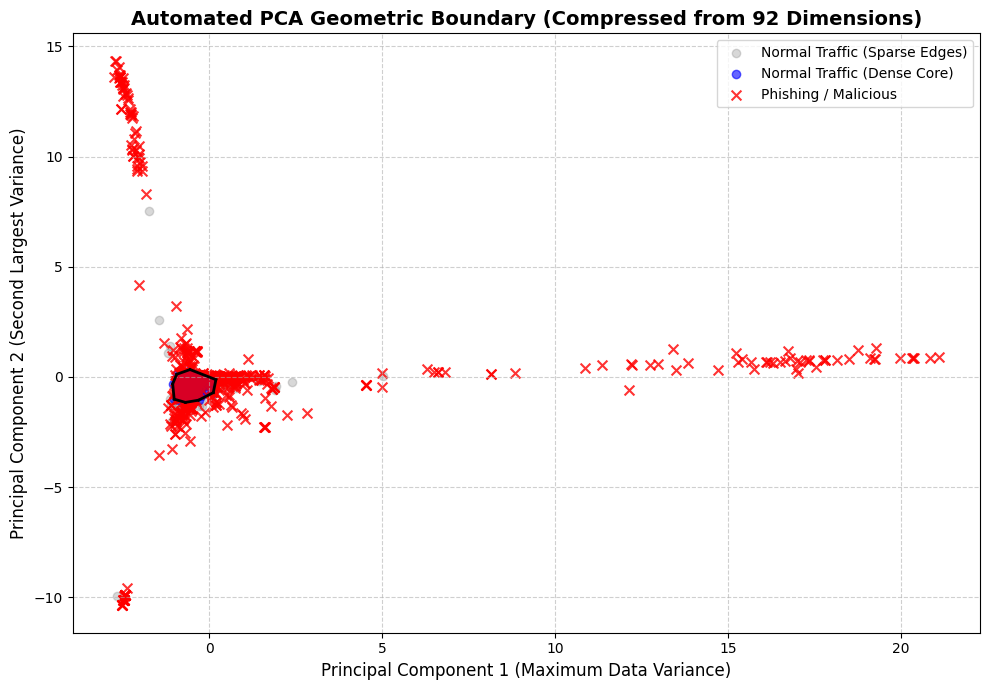

In [6]:
#  Cell 3 : Step 2 - Run (The Visual Analysis)
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull, Delaunay

# --- STEP 3: ANALYSIS & VISUALIZATION (THE GEOMETRIC VAULT) ---

# 1. Isolate the densest 85% of the normal traffic in our new PCA space
def get_core_data(data_points, core_fraction=0.85):
    centroid = np.mean(data_points, axis=0)
    distances = np.linalg.norm(data_points - centroid, axis=1)
    threshold = np.percentile(distances, core_fraction * 100)
    return data_points[distances <= threshold], data_points[distances > threshold]

core_legit, sparse_legit = get_core_data(legit_pca)

# 2. Build the Mathematical Boundaries
pca_hull = ConvexHull(core_legit)
pca_del = Delaunay(core_legit)

# 3. Run Inference: Test the Phishing Attacks against the 92-Dimension Shadow
caught = 0
for p in phish_pca:
    # If the attack falls outside the PCA geometric safe zone, flag it!
    if pca_del.find_simplex(p) < 0:
        caught += 1

print(f"=== PCA-Driven Geometric Detection ===")
print(f"Total N-Dimensions Compressed: {len(numeric_cols)}")
print(f"Total Attacks Blocked: {caught} / {len(phish_pca)} ({(caught/len(phish_pca))*100:.1f}%)")
print("-" * 40)

# 4. Generate the Final Publication-Ready Graph
plt.figure(figsize=(10, 7))

# Plot the data points
plt.scatter(sparse_legit[:, 0], sparse_legit[:, 1], c='gray', alpha=0.3, label='Normal Traffic (Sparse Edges)')
plt.scatter(core_legit[:, 0], core_legit[:, 1], c='blue', alpha=0.6, label='Normal Traffic (Dense Core)')
plt.scatter(phish_pca[:, 0], phish_pca[:, 1], c='red', marker='x', alpha=0.8, s=50, label='Phishing / Malicious')

# Draw the boundary lines of the Convex Hull
for simplex in pca_hull.simplices:
    plt.plot(core_legit[simplex, 0], core_legit[simplex, 1], 'k-', lw=2)

# Fill the safe zone with a light blue tint
plt.fill(core_legit[pca_hull.vertices, 0], core_legit[pca_hull.vertices, 1], color='blue', alpha=0.15)

# Labels and Formatting
plt.title(f"Automated PCA Geometric Boundary (Compressed from {len(numeric_cols)} Dimensions)", fontsize=14, fontweight='bold')
plt.xlabel("Principal Component 1 (Maximum Data Variance)", fontsize=12)
plt.ylabel("Principal Component 2 (Second Largest Variance)", fontsize=12)
plt.legend(loc='best', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

# Save and Show
plt.tight_layout()
plt.savefig("results/generated/PCA_Geometric_Boundary_Final.png", dpi=300)
plt.show()